# Optimasi Portofolio

Tahap ini membentuk portofolio menggunakan prediksi XGBoost dan historical mean. Keduanya dibandingkan berdasarkan return, risiko, dan perubahan bobot saat prediksi return diubah.

## Persiapan

Library, batas bobot saham, jumlah hari pada historical window, dan risk-free rate disiapkan sebelum perhitungan. Perubahan prediksi untuk uji sensitivitas juga ditentukan pada bagian ini.

In [1]:
# import library
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

import sys
# biar file .py di folder utama bisa di-import dari folder notebooks
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline_utils import build_exchange_calendar, calculate_held_weights, show_table

from notebook_config import (
    blue,
    configure_notebook,
    orange,
    palette,
    tickers,
)


In [2]:
# mengatur folder dan parameter portofolio
root_dir, output_dir = configure_notebook()
processed_dir = root_dir / "data" / "processed"
output_dir = output_dir / "research"
output_dir.mkdir(parents=True, exist_ok=True)

# membatasi alokasi baru sampai 20 persen per saham
max_weight = 0.20

# memakai 20 return terakhir untuk historical mean dan covariance
lookback = 20

# menentukan perubahan prediksi dalam basis point
shocks_bp = (-10, -5, -1, 1, 5, 10)

# menggunakan 252 hari perdagangan untuk konversi harian dan tahunan
trading_days_per_year = 252.0

# membatasi optimasi sampai 1.000 iterasi
optimizer_max_iterations = 1000

# menentukan toleransi penghentian perhitungan pada solver SLSQP
optimizer_tolerance = 1e-9

# memakai risk-free rate tahunan sesuai kuartal keputusan
risk_free_rates = (0.0600, 0.0575, 0.0550, 0.0475)

# merapikan nama kolom hasil backtest pada tabel
display_names = {
    "Annualized Volatility (%)": "Annualized Volatility (%)",
    "Cumulative Return (%)": "Cumulative Return (%)",
    "Historical Mean 20D-Markowitz (Daily t+1)": "Historical Mean 20D",
    "Max Cumulative Return (%)": "Maximum Cumulative Return (%)",
    "Maximum Drawdown (%)": "Maximum Drawdown (%)",
    "Min Cumulative Return (%)": "Minimum Cumulative Return (%)",
    "Persentil_95": "95th Percentile",
    "Quarter": "Quarter",
    "Kuartal": "Quarter",
    "Realized Return Historical Mean (%)": "Realized Return Historical Mean (%)",
    "Realized Return XGBoost-Markowitz (%)": "Realized Return XGBoost (%)",
    "Rf Kuartalan (%)": "Akumulasi Risk-free Rate (%)",
    "Selisih Keunggulan (%)": "Selisih Return (Percentage Points)",
    "Sharpe Ratio": "Sharpe Ratio",
    "XGBoost-Markowitz (Daily t+1)": "XGBoost",
    "cum_hist": "Cumulative Return Historical Mean",
    "cum_xgb": "Cumulative Return XGBoost",
    "decision_date": "Tanggal Keputusan",
    "realized_date": "Tanggal Realisasi",
    "return_hist": "Return Historical Mean",
    "return_xgb": "Return XGBoost",
    "rf_daily": "Daily Risk-free Rate",
    "snapshot_date": "Tanggal Observasi",
    "Tanggal keputusan": "Tanggal Keputusan",
    "Tanggal realisasi": "Tanggal Realisasi",
    "Tanggal observasi": "Tanggal Observasi",
    "Saham diubah": "Ticker yang Diubah",
    "Perubahan prediksi (bp)": "Prediction Shock (bp)",
    "Besar perubahan prediksi (bp)": "Absolute Prediction Shock (bp)",
    "Perubahan alokasi (%)": "Allocation Change (%)",
    "Return kumulatif (%)": "Cumulative Return (%)"
}


## Menghitung Bobot Portofolio

Bobot dihitung dengan memaksimalkan Sharpe Ratio menggunakan covariance dari 20 return terakhir. Total bobot ditetapkan sebesar 100% dengan batas 20% per saham saat rebalancing, yaitu saat alokasi dihitung ulang.

In [3]:
# optimasi Markowitz, mencari bobot dengan Sharpe Ratio paling tinggi
# Sharpe = (return portofolio - risk-free) / volatilitas portofolio
# syaratnya total bobot 100 persen, tiap saham 0 sampai 20 persen, tanpa short selling
def optimize_max_sharpe(expected_returns, covariance, risk_free_daily, max_weight=0.20):
    """Cari bobot dengan Sharpe tertinggi sesuai batas alokasi penelitian."""
    expected_returns = np.asarray(expected_returns, dtype=float)
    covariance = np.asarray(covariance, dtype=float)
    n_assets = len(expected_returns)

    # mengecek apakah batas bobot memungkinkan seluruh modal dialokasikan
    if n_assets * max_weight < 1.0 - 1e-12:
        raise ValueError('Batas maksimum weight tidak memungkinkan total weight 100%')

    def calculate_negative_sharpe(weights):
        portfolio_return = weights @ expected_returns
        portfolio_variance = weights @ covariance @ weights
        # memberi penalti jika variance terlalu kecil untuk menghitung Sharpe Ratio
        if portfolio_variance <= 1e-16:
            return 1e6
        return -((portfolio_return - risk_free_daily) / np.sqrt(portfolio_variance))

    # mencari Sharpe tertinggi dengan meminimalkan nilai negatifnya
    result = minimize(
        calculate_negative_sharpe,
        np.full(n_assets, 1.0 / n_assets),
        method="SLSQP",
        bounds=[(0.0, max_weight)] * n_assets,
        constraints=[{"type": "eq", "fun": lambda weights: weights.sum() - 1.0}],
        options={"maxiter": optimizer_max_iterations, "ftol": optimizer_tolerance},
    )
    if not result.success or not np.isfinite(result.x).all():
        raise RuntimeError(f"Optimization gagal: {result.message}")
    # membatasi hasil solver ke rentang bobot yang diizinkan
    candidate = np.clip(result.x, 0.0, max_weight)
    residual = 1.0 - candidate.sum()
    if abs(residual) > 1e-6:
        raise RuntimeError(f"Optimization menghasilkan weight yang tidak memenuhi batas: {result.message}")
    # memperbaiki selisih kecil akibat perhitungan numerik agar total bobot 100 persen
    for index in range(n_assets):
        if abs(residual) <= 1e-12:
            break
        adjustment = min(residual, max_weight - candidate[index]) if residual > 0 else max(residual, -candidate[index])
        candidate[index] += adjustment
        residual -= adjustment
    if abs(candidate.sum() - 1.0) > 1e-9 or candidate.max() > max_weight + 1e-12:
        raise RuntimeError('Perbaikan weight tidak memenuhi batas portfolio')
    return candidate


## Menentukan Risk-free Rate

Risk-free rate tahunan dipilih berdasarkan kuartal tanggal keputusan. Nilainya dibagi dengan 252 untuk digunakan dalam perhitungan Sharpe Ratio harian.

In [4]:
def get_risk_free_rate(date):
    """Pilih risk-free rate tahunan sesuai kuartal tanggal keputusan."""
    month = pd.Timestamp(date).month
    if month <= 3:
        return risk_free_rates[0]
    if month <= 6:
        return risk_free_rates[1]
    if month <= 9:
        return risk_free_rates[2]
    return risk_free_rates[3]


## Load Data dan Tanggal Rebalancing

Kalender saham dibaca dari panel_calendar.parquet dan prediksi dari predictions_2025.parquet. Tanggal keputusan dipasangkan dengan hari bursa berikutnya, lalu urutan saham disamakan pada data return dan prediksi.

In [5]:
# membaca kalender harga (notebook 02) dan prediksi 2025 (notebook 03)
master = pd.read_parquet(processed_dir / "panel_calendar.parquet")
predictions = pd.read_parquet(processed_dir / "predictions_2025.parquet")
master["snapshot_date"] = pd.to_datetime(master["snapshot_date"])
predictions["snapshot_date"] = pd.to_datetime(predictions["snapshot_date"])
predictions["target_date"] = pd.to_datetime(predictions["target_date"])

if set(master["Kode Saham"].unique()) != set(tickers) or set(predictions["Kode Saham"].unique()) != set(tickers):
    raise ValueError('master panel data atau prediksi belum sesuai 11 saham. Jalankan Notebook 01 sampai 03 dahulu.')
# menyamakan urutan saham pada seluruh input portofolio
# tabel return harian, baris tanggal dan kolom saham
return_panel = master.pivot(index="snapshot_date", columns="Kode Saham", values="simple_return")[tickers].sort_index()


In [6]:
# memasangkan tanggal keputusan t dengan tanggal realisasi t+1
# memasangkan tanggal keputusan dengan tanggal realisasi berikutnya
decision_dates, target_date_map = build_exchange_calendar(return_panel, start_date="2025-01-01", end_date="2025-12-31")
prediction_panel = predictions.pivot(index="snapshot_date", columns="Kode Saham", values="y_pred")[tickers].reindex(decision_dates)
# mengecek saham yang diperdagangkan pada hari keputusan
trade_panel = master.pivot(index="snapshot_date", columns="Kode Saham", values="Volume")[tickers].gt(0)
if return_panel.loc[decision_dates, tickers].isna().any().any() or return_panel.loc[target_date_map, tickers].isna().any().any():
    raise ValueError("Close kalender belum lengkap untuk penilaian portofolio")
if len(decision_dates) == 0:
    raise ValueError("Tidak ada tanggal keputusan 2025")

date_summary = pd.DataFrame({
    "Pengamatan": ["Pertama", "Terakhir"],
    "Tanggal keputusan": [decision_dates.min(), decision_dates.max()],
    "Tanggal realisasi": [target_date_map.iloc[0], target_date_map.iloc[-1]],
})
show_table(date_summary, display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Pengamatan,Tanggal Keputusan,Tanggal Realisasi
0,Pertama,2025-01-02,2025-01-03
1,Terakhir,2025-12-29,2025-12-30


## Backtest Portofolio

Backtest menghitung hasil alokasi menggunakan data historis. Pada setiap tanggal keputusan, bobot dibentuk dari prediksi dan 20 return terakhir yang sudah tersedia. Return hari bursa berikutnya digunakan untuk menghitung hasil portofolio.

Jika ada saham yang tidak diperdagangkan atau prediksinya belum lengkap pada hari keputusan, alokasi sebelumnya dipertahankan. Bobotnya diperbarui mengikuti perubahan nilai aset.

In [7]:
# backtest harian 2025, di tiap tanggal keputusan:
# 1. portofolio XGBoost pakai prediksi model, pembandingnya pakai rata-rata 20 return terakhir
# 2. risiko pakai kovarians 20 return terakhir, sama untuk dua portofolio
# 3. mencari bobot Max Sharpe lalu menghitung hasilnya pakai return aktual t+1
# kalau ada saham yang tidak ditransaksikan, bobot lama tetap dipakai
daily_records = []
xgb_weight_records = []
historical_weight_records = []

previous_xgb_weights = None
previous_historical_weights = None
previous_asset_returns = None
execution_rows = []

for decision_date in decision_dates:
    realized_date = target_date_map.loc[decision_date]
    # mengambil riwayat return hanya sampai hari keputusan
    historical_window = return_panel.loc[:decision_date].dropna().tail(lookback)
    if len(historical_window) != lookback:
        raise ValueError(f"Window return {decision_date.date()} tidak berisi tepat {lookback} observasi")

    # menggunakan window return yang sama untuk covariance dan historical mean
    covariance = historical_window.cov(ddof=1)
    historical_expected_return = historical_window.mean()
    xgb_expected_return = prediction_panel.loc[decision_date]
    risk_free_daily = get_risk_free_rate(decision_date) / trading_days_per_year

    # melakukan rebalancing jika seluruh saham diperdagangkan dan prediksi lengkap
    can_rebalance = bool(trade_panel.loc[decision_date, tickers].all() and xgb_expected_return.notna().all())
    if can_rebalance:
        xgb_weights = optimize_max_sharpe(xgb_expected_return.values, covariance.values, risk_free_daily, max_weight)
        historical_weights = optimize_max_sharpe(historical_expected_return.values, covariance.values, risk_free_daily, max_weight)
    else:
        if previous_xgb_weights is None:
            raise ValueError("Tanggal awal belum memungkinkan pembentukan portofolio")
        # mempertahankan alokasi sebelumnya dan memperbarui bobot mengikuti return aset
        xgb_weights = calculate_held_weights(previous_xgb_weights, previous_asset_returns)
        historical_weights = calculate_held_weights(previous_historical_weights, previous_asset_returns)
    execution_rows.append({"Decision Date": decision_date, "Rebalanced": can_rebalance,
                           "Unavailable Tickers": ", ".join(trade_panel.columns[~trade_panel.loc[decision_date]])})

    # menghitung hasil alokasi memakai return hari berikutnya
    realized_asset_returns = return_panel.loc[realized_date].values
    realized_xgb = xgb_weights @ realized_asset_returns
    realized_historical = historical_weights @ realized_asset_returns
    previous_xgb_weights = xgb_weights.copy()
    previous_historical_weights = historical_weights.copy()
    previous_asset_returns = realized_asset_returns.copy()
    quarter = f"Q{decision_date.quarter} 2025"

    daily_records.append({
        "decision_date": decision_date,
        "realized_date": realized_date,
        "snapshot_date": realized_date,
        "rf_daily": risk_free_daily,
        "return_xgb": realized_xgb,
        "return_hist": realized_historical,
        "rebalanced": can_rebalance,
    })
    xgb_weight_records.append({"decision_date": decision_date, "realized_date": realized_date, "Quarter": quarter, **dict(zip(tickers, xgb_weights))})
    historical_weight_records.append({"decision_date": decision_date, "realized_date": realized_date, "Quarter": quarter, **dict(zip(tickers, historical_weights))})


In [8]:
# menyimpan catatan eksekusi, menghitung return kumulatif, dan rata-rata bobot per kuartal
execution_audit = pd.DataFrame(execution_rows)
execution_audit.to_csv(output_dir / "portfolio_execution_2025.csv", index=False, date_format="%Y-%m-%d")
# menggabungkan hasil harian dan menghitung cumulative return
portfolio_daily = pd.DataFrame(daily_records)
portfolio_daily["cum_xgb"] = (1.0 + portfolio_daily["return_xgb"]).cumprod() - 1.0
portfolio_daily["cum_hist"] = (1.0 + portfolio_daily["return_hist"]).cumprod() - 1.0

xgb_daily_weights = pd.DataFrame(xgb_weight_records)
historical_daily_weights = pd.DataFrame(historical_weight_records)
# meringkas bobot harian menjadi rata-rata per kuartal
xgb_quarterly_weights = xgb_daily_weights.groupby("Quarter", sort=False)[tickers].mean().reset_index()
historical_quarterly_weights = historical_daily_weights.groupby("Quarter", sort=False)[tickers].mean().reset_index()


In [9]:
# menyimpan return dan bobot untuk analisis berikutnya
portfolio_daily.to_parquet(output_dir / "portfolio_daily_returns_2025.parquet", index=False)
xgb_daily_weights.to_parquet(output_dir / "portfolio_xgb_daily_weights_2025.parquet", index=False)
historical_daily_weights.to_parquet(output_dir / "portfolio_hist_daily_weights_2025.parquet", index=False)
xgb_quarterly_weights.to_parquet(output_dir / "portfolio_xgb_quarterly_weights_2025.parquet", index=False)
historical_quarterly_weights.to_parquet(output_dir / "portfolio_hist_quarterly_weights_2025.parquet", index=False)

# memastikan total bobot setiap portofolio sebesar 100 persen
assert np.allclose(xgb_daily_weights[tickers].sum(axis=1), 1.0, atol=1e-7)
assert np.allclose(historical_daily_weights[tickers].sum(axis=1), 1.0, atol=1e-7)
# mengecek batas 20 persen pada alokasi yang baru dibentuk
assert xgb_daily_weights.loc[portfolio_daily["rebalanced"], tickers].to_numpy().max() <= max_weight + 1e-7
assert historical_daily_weights.loc[portfolio_daily["rebalanced"], tickers].to_numpy().max() <= max_weight + 1e-7

portfolio_daily.shape[0]


235

In [10]:
# menampilkan contoh return harian dan cumulative return kedua portofolio
show_table(portfolio_daily[["decision_date", "realized_date", "return_xgb", "return_hist", "cum_xgb", "cum_hist"]].head(), display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Tanggal Keputusan,Tanggal Realisasi,Return XGBoost,Return Historical Mean,Cumulative Return XGBoost,Cumulative Return Historical Mean
0,2025-01-02,2025-01-03,0.00210575,0.0047758,0.00210575,0.0047758
1,2025-01-03,2025-01-06,-0.0104448,-0.0159164,-0.00836108,-0.0112166
2,2025-01-06,2025-01-07,-0.00555692,-0.00144052,-0.0138715,-0.012641
3,2025-01-07,2025-01-08,-0.00248244,-0.0073601,-0.0163196,-0.019908
4,2025-01-08,2025-01-09,0.00723276,0.0137454,-0.00920483,-0.00643622


In [11]:
# menampilkan bobot XGBoost pada lima tanggal keputusan terakhir
show_table(xgb_daily_weights.drop(columns="Quarter").tail(), display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Tanggal Keputusan,Tanggal Realisasi,BBCA,BBNI,BBRI,BBTN,BDMN,BJBR,BMRI,BNGA,BNLI,BTPS,PNBN
230,2025-12-19,2025-12-22,0,0.2,0,0.0913209,0.2,0.0889948,0.0181426,0.2,0.2,0,0.0015417
231,2025-12-22,2025-12-23,3.60525e-16,0.2,1.12965e-14,0.2,0.2,0,0.2,0.2,6.61028e-16,3.51696e-15,0
232,2025-12-23,2025-12-24,1.46479e-15,0.2,1.58554e-13,0.2,0.2,1.18901e-15,0.2,0.2,2.23396e-15,2.50893e-14,2.25605e-15
233,2025-12-24,2025-12-29,2.29117e-12,0.2,0,0.2,0.2,0,0.2,0.2,0,0,0
234,2025-12-29,2025-12-30,0,0.2,0,0.2,0.2,0,0.2,0.2,0,0,0


## Evaluasi Portofolio

Kinerja kedua portofolio dibandingkan menggunakan cumulative return, maximum drawdown, volatility, dan Sharpe Ratio. Volatility dan Sharpe Ratio dikonversi ke nilai tahunan menggunakan 252 hari perdagangan.

In [12]:
# metrik kinerja: return kumulatif, volatilitas, Sharpe Ratio, dan maximum drawdown
def compute_performance(return_series, risk_free_series):
    """Ringkas kinerja dari return harian dan risk-free rate pada periode yang sama."""
    cumulative = (1.0 + return_series).cumprod() - 1.0
    equity = 1.0 + cumulative
    # menghitung drawdown dari puncak nilai portofolio
    drawdown = equity / equity.cummax() - 1.0
    # mengurangi return harian dengan risk-free rate pada tanggal yang sama
    excess = return_series.to_numpy() - risk_free_series.to_numpy()
    return {
        "Cumulative Return (%)": cumulative.iloc[-1] * 100.0,
        "Annualized Volatility (%)": return_series.std(ddof=1) * np.sqrt(trading_days_per_year) * 100.0,
        "Sharpe Ratio": excess.mean() / excess.std(ddof=1) * np.sqrt(trading_days_per_year),
        "Maximum Drawdown (%)": drawdown.min() * 100.0,
        "Max Cumulative Return (%)": cumulative.max() * 100.0,
        "Min Cumulative Return (%)": cumulative.min() * 100.0,
    }

performance_summary = pd.DataFrame({
    "XGBoost-Markowitz (Daily t+1)": compute_performance(portfolio_daily["return_xgb"], portfolio_daily["rf_daily"]),
    "Historical Mean 20D-Markowitz (Daily t+1)": compute_performance(portfolio_daily["return_hist"], portfolio_daily["rf_daily"]),
})
performance_summary.to_parquet(output_dir / "portfolio_performance_summary.parquet")

show_table(performance_summary, display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,XGBoost,Historical Mean 20D
Cumulative Return (%),34.808,26.0095
Annualized Volatility (%),21.1624,23.5017
Sharpe Ratio,1.361,0.940
Maximum Drawdown (%),-9.37814,-11.9452
Maximum Cumulative Return (%),34.808,29.864
Minimum Cumulative Return (%),-2.74171,-1.9908


## Return per Kuartal

Return harian digabungkan untuk menghitung return setiap kuartal. Return XGBoost dan historical mean ditampilkan bersama selisihnya serta akumulasi risk-free rate pada periode yang sama.

In [13]:
# return tiap kuartal untuk dua portofolio dan selisihnya
# menggabungkan return harian dengan perkalian bertahap pada setiap kuartal
quarterly_rows = []
for quarter, group in portfolio_daily.groupby(portfolio_daily["decision_date"].dt.quarter, sort=True):
    xgb_return = (1.0 + group["return_xgb"]).prod() - 1.0
    historical_return = (1.0 + group["return_hist"]).prod() - 1.0
    quarterly_rows.append({
        "Kuartal": f"Q{quarter} 2025",
        "Rf Kuartalan (%)": group["rf_daily"].sum() * 100.0,
        "Realized Return XGBoost-Markowitz (%)": xgb_return * 100.0,
        "Realized Return Historical Mean (%)": historical_return * 100.0,
        "Selisih Keunggulan (%)": (xgb_return - historical_return) * 100.0,
    })
quarterly_returns = pd.DataFrame(quarterly_rows)
quarterly_returns.to_parquet(output_dir / "quarterly_returns_summary.parquet", index=False)

show_table(quarterly_returns, display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Quarter,Akumulasi Risk-free Rate (%),Realized Return XGBoost (%),Realized Return Historical Mean (%),Selisih Return (Percentage Points)
0,Q1 2025,1.38095,1.62167,4.00703,-2.38537
1,Q2 2025,1.16369,15.8017,15.4237,0.377952
2,Q3 2025,1.39683,7.71341,4.50995,3.20346
3,Q4 2025,1.16865,6.35178,0.435643,5.91613


## Uji Sensitivitas

Uji sensitivitas dilakukan untuk melihat perubahan bobot ketika prediksi return satu saham diubah. Pengujian menggunakan tanggal keputusan pertama setiap bulan dengan perubahan sebesar -10, -5, -1, 1, 5, atau 10 basis point. Satu basis point setara dengan 0,0001 pada return desimal.

Covariance, risk-free rate, dan batas bobot tetap pada setiap skenario. Perubahan alokasi dihitung dengan $D=\frac{1}{2}\sum_j |w_j^{\mathrm{skenario}}-w_j^{\mathrm{awal}}|$, lalu dikalikan 100 untuk ditampilkan dalam persen.

In [14]:
# fungsi bantu buat menguji sensitivitas
def select_first_monthly_decisions(dates):
    """Ambil tanggal keputusan pertama yang tersedia pada setiap bulan."""
    dates = pd.DatetimeIndex(dates).sort_values()
    return dates[~dates.to_period("M").duplicated()]

def calculate_allocation_change(original_weights, scenario_weights):
    """Hitung bagian modal yang berpindah antar saham, dalam persen."""
    original = np.asarray(original_weights, dtype=float)
    scenario = np.asarray(scenario_weights, dtype=float)
    if original.shape != scenario.shape:
        raise ValueError('Kedua vektor weight harus memiliki panjang yang sama')
    # menghitung setengah jumlah selisih absolut bobot dan mengubah ke persen
    return float(0.5 * np.abs(scenario - original).sum() * 100.0)


In [15]:
# uji sensitivitas: prediksi satu saham digeser -10 sampai +10 basis point (1 bp = 0,01 persen)
# lalu bobot dihitung ulang dan dilihat berapa persen modal yang pindah
# dicoba di tanggal keputusan pertama tiap bulan
# mengambil tanggal keputusan pertama tiap bulan untuk menguji sensitivitas
monthly_dates = select_first_monthly_decisions(decision_dates)
baseline_weights = xgb_daily_weights.set_index("decision_date")
risk_free_by_date = portfolio_daily.set_index("decision_date")["rf_daily"]

rows = []
for decision_date in monthly_dates:
    window = return_panel.loc[:decision_date, tickers].dropna().tail(lookback)
    if len(window) != lookback:
        raise ValueError(f"Riwayat return belum lengkap pada {decision_date.date()}")

    covariance = window.cov(ddof=1).to_numpy()
    prediction = prediction_panel.loc[decision_date, tickers].to_numpy(dtype=float)
    original = baseline_weights.loc[decision_date, tickers].to_numpy(dtype=float)
    risk_free_daily = float(risk_free_by_date.loc[decision_date])

    for asset_index, ticker in enumerate(tickers):
        for shock_bp in shocks_bp:
            # mengubah prediksi satu saham pada setiap skenario
            changed_prediction = prediction.copy()
            # mengubah basis point ke return desimal sebelum ditambahkan
            changed_prediction[asset_index] += shock_bp / 10_000
            # menghitung ulang bobot dengan prediksi yang sudah diubah
            scenario = optimize_max_sharpe(
                changed_prediction, covariance, risk_free_daily, max_weight
            )
            rows.append({
                "Tanggal keputusan": decision_date,
                "Saham diubah": ticker,
                "Perubahan prediksi (bp)": shock_bp,
                "Perubahan alokasi (%)": calculate_allocation_change(original, scenario),
            })


In [16]:
# ringkasan uji sensitivitas: median, persentil 95, dan maksimum
sensitivity_detail = pd.DataFrame(rows)
# memastikan semua kombinasi tanggal, saham, dan perubahan prediksi sudah dihitung
expected_scenarios = len(monthly_dates) * len(tickers) * len(shocks_bp)
if len(sensitivity_detail) != expected_scenarios:
    raise AssertionError('Jumlah skenario sensitivity analysis tidak sesuai rancangan')

# meringkas perubahan alokasi berdasarkan besar perubahan prediksi
sensitivity_summary = (
    sensitivity_detail
    .assign(**{"Besar perubahan prediksi (bp)": lambda df: df["Perubahan prediksi (bp)"].abs()})
    .groupby("Besar perubahan prediksi (bp)")["Perubahan alokasi (%)"]
    .agg(Median="median", Persentil_95=lambda values: values.quantile(0.95), Maksimum="max")
    .reset_index()
)

sensitivity_detail.to_parquet(
    output_dir / "portfolio_prediction_sensitivity_detail_2025.parquet", index=False
)
sensitivity_summary.to_csv(
    output_dir / "portfolio_prediction_sensitivity_summary_2025.csv", index=False
)

show_table(pd.DataFrame({"Keterangan": ["Tanggal sampel", "Skenario"], "Nilai": [len(monthly_dates), len(sensitivity_detail)]}), display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Keterangan,Nilai
0,Tanggal sampel,12
1,Skenario,792


In [17]:
# menampilkan median, persentil ke-95, dan perubahan alokasi terbesar
show_table(sensitivity_summary, display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Absolute Prediction Shock (bp),Median,95th Percentile,Maksimum
0,1,2.42656e-06,2.40723,12.7632
1,5,3.28997e-05,12.7632,20
2,10,0.000207794,20,20


In [18]:
# menampilkan lima skenario dengan perubahan alokasi terbesar
show_table(sensitivity_detail.nlargest(5, "Perubahan alokasi (%)").reset_index(drop=True), display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Tanggal Keputusan,Ticker yang Diubah,Prediction Shock (bp),Allocation Change (%)
0,2025-07-01,BMRI,-10,20
1,2025-07-01,BJBR,5,20
2,2025-07-01,BJBR,10,20
3,2025-07-01,BBRI,5,20
4,2025-07-01,BBRI,10,20


## Perbandingan Portofolio Tanpa BNLI

Backtest XGBoost diulang menggunakan sepuluh saham setelah BNLI dikeluarkan. Bobot dihitung kembali, lalu cumulative return dibandingkan dengan portofolio sebelas saham.

In [19]:
# backtest XGBoost diulang tanpa BNLI
# buat melihat seberapa besar hasil portofolio bergantung sama BNLI
# mengulangi backtest menggunakan sepuluh saham tanpa BNLI
remaining_tickers = [ticker for ticker in tickers if ticker != "BNLI"]
exclusion_returns = []
for decision_date in decision_dates:
    realized_date = target_date_map.loc[decision_date]
    # mengambil riwayat return hanya sampai hari keputusan
    historical_window = return_panel.loc[:decision_date, remaining_tickers].dropna().tail(lookback)
    covariance = historical_window.cov(ddof=1)
    expected_return = prediction_panel.loc[decision_date, remaining_tickers]
    risk_free_daily = get_risk_free_rate(decision_date) / trading_days_per_year
    weights_without_bnli = optimize_max_sharpe(
        expected_return.values, covariance.values, risk_free_daily, max_weight
    )
    exclusion_returns.append(weights_without_bnli @ return_panel.loc[realized_date, remaining_tickers].values)

# membandingkan cumulative return dengan dan tanpa BNLI
without_bnli_return = (np.prod(1.0 + np.array(exclusion_returns)) - 1.0) * 100.0
exclusion_summary = pd.DataFrame([
    {"Skenario": "11 saham", "Return kumulatif (%)": performance_summary.loc["Cumulative Return (%)", "XGBoost-Markowitz (Daily t+1)"]},
    {"Skenario": "10 saham tanpa BNLI", "Return kumulatif (%)": without_bnli_return},
])
exclusion_summary.to_parquet(output_dir / "portfolio_robustness_2025.parquet", index=False)
show_table(exclusion_summary, display_names=display_names, row_formats={"Sharpe Ratio": "{:.3f}"})


,Skenario,Cumulative Return (%)
0,11 saham,34.808
1,10 saham tanpa BNLI,-2.59237


## Grafik Kinerja Portofolio

Grafik menampilkan cumulative return dan drawdown kedua portofolio selama 2025. Perubahan bobot harian ditampilkan pada grafik berikutnya.

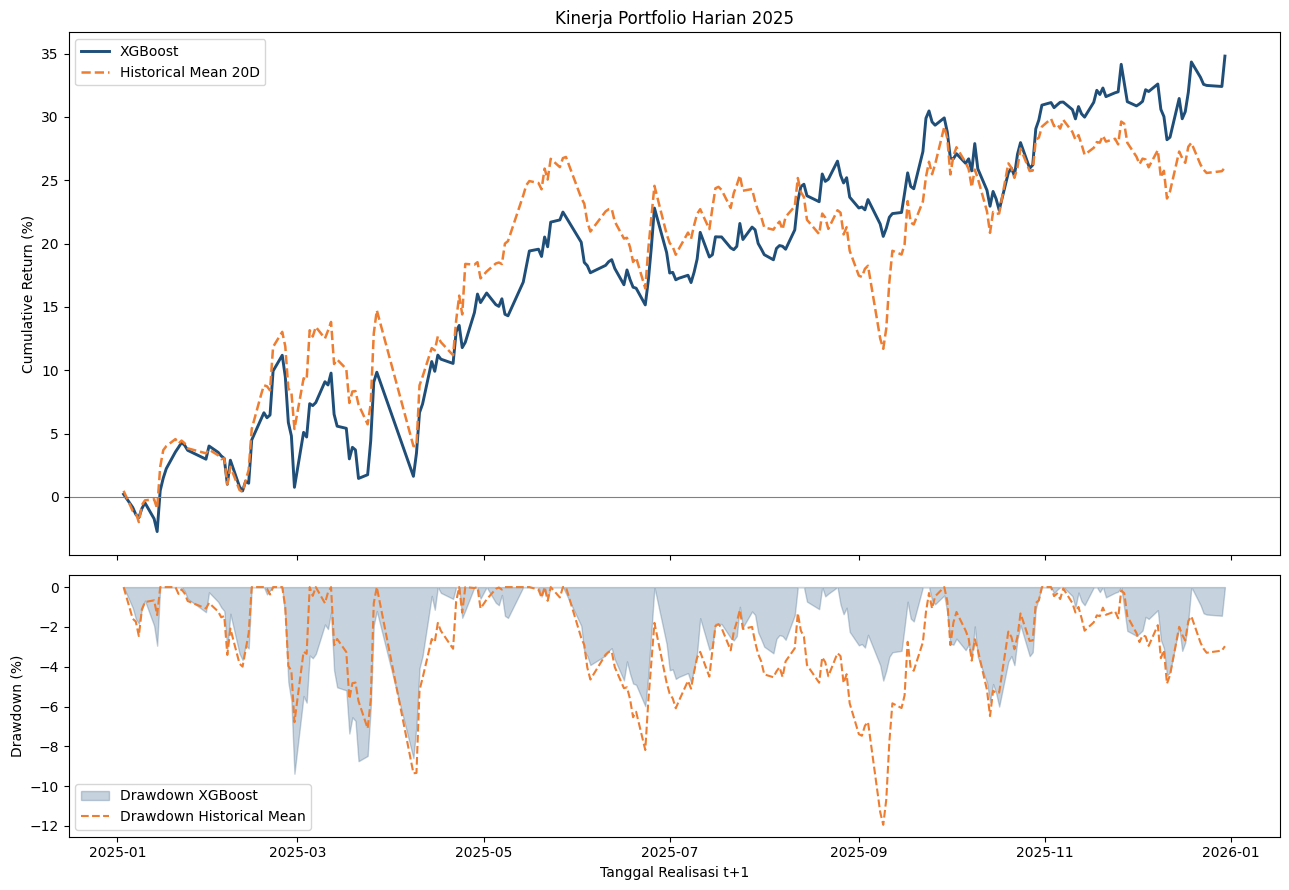

In [20]:
# grafik return kumulatif di atas dan drawdown di bawah
fig, (return_axis, drawdown_axis) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
return_axis.plot(portfolio_daily["realized_date"], portfolio_daily["cum_xgb"] * 100, color=blue, linewidth=2.1, label="XGBoost")
return_axis.plot(portfolio_daily["realized_date"], portfolio_daily["cum_hist"] * 100, color=orange, linewidth=1.8, linestyle="--", label='Historical Mean 20D')
return_axis.axhline(0, color="gray", linewidth=0.8)
return_axis.set_ylabel("Cumulative Return (%)")
return_axis.set_title('Kinerja Portfolio Harian 2025')
return_axis.legend()

# menghitung penurunan nilai portofolio dari puncak yang sudah dicapai
xgb_equity = 1.0 + portfolio_daily["cum_xgb"]
hist_equity = 1.0 + portfolio_daily["cum_hist"]
xgb_drawdown = xgb_equity / xgb_equity.cummax() - 1.0
hist_drawdown = hist_equity / hist_equity.cummax() - 1.0
drawdown_axis.fill_between(portfolio_daily["realized_date"], xgb_drawdown * 100, 0, color=blue, alpha=0.25, label='Drawdown XGBoost')
drawdown_axis.plot(portfolio_daily["realized_date"], hist_drawdown * 100, color=orange, linestyle="--", label='Drawdown Historical Mean')
drawdown_axis.set_ylabel('Drawdown (%)')
drawdown_axis.set_xlabel("Tanggal Realisasi t+1")
drawdown_axis.legend()

fig.tight_layout()
plt.show()


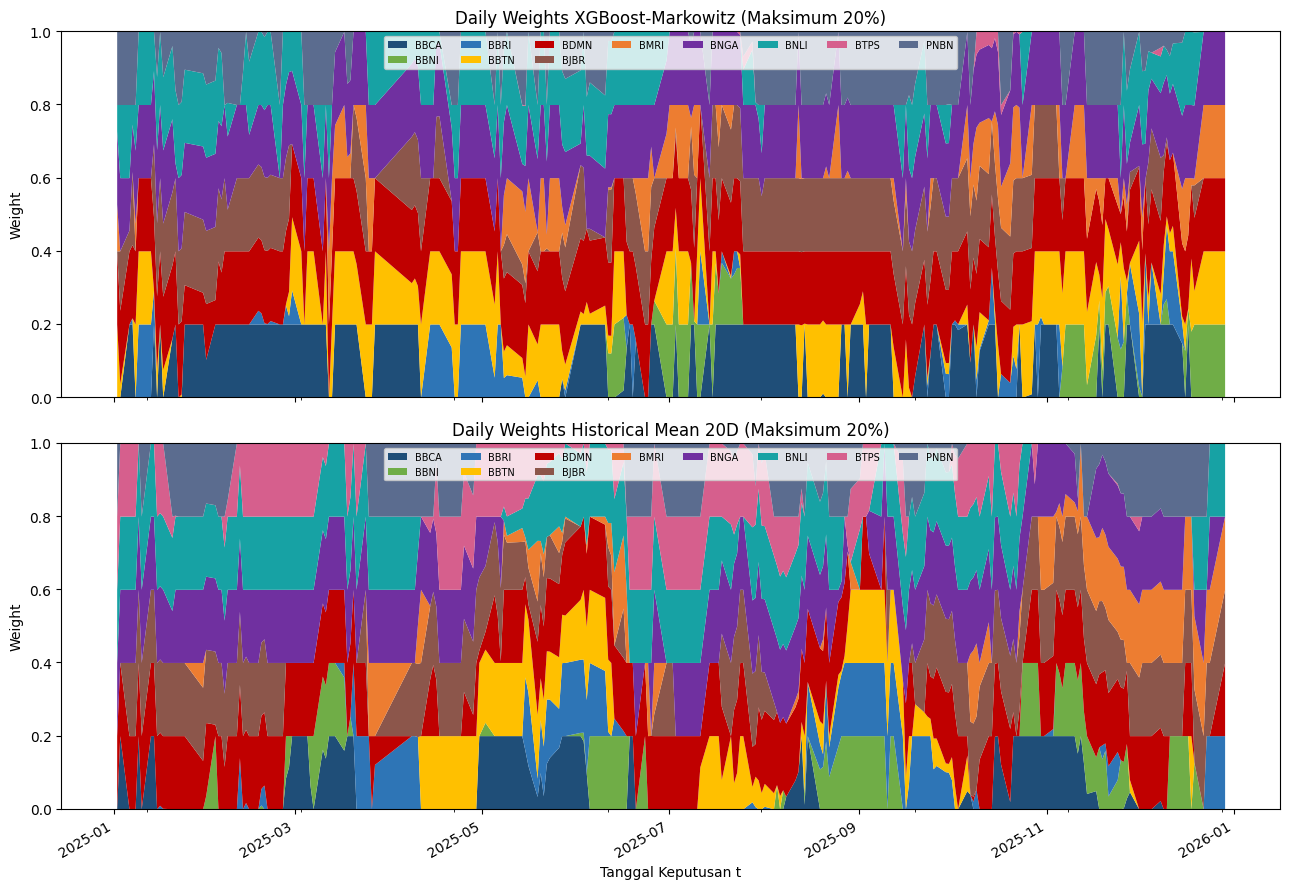

In [21]:
# menampilkan perubahan komposisi portofolio sepanjang periode pengujian
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
xgb_plot = xgb_daily_weights.set_index("decision_date")[tickers]
hist_plot = historical_daily_weights.set_index("decision_date")[tickers]
xgb_plot.plot.area(ax=axes[0], color=[palette[ticker] for ticker in tickers], linewidth=0)
hist_plot.plot.area(ax=axes[1], color=[palette[ticker] for ticker in tickers], linewidth=0)
axes[0].set_title('Daily Weights XGBoost-Markowitz (Maksimum 20%)')
axes[1].set_title('Daily Weights Historical Mean 20D (Maksimum 20%)')
for axis in axes:
    axis.set_ylabel('Weight')
    axis.set_ylim(0, 1)
    axis.legend(ncol=8, fontsize=7, loc="upper center")
axes[1].set_xlabel("Tanggal Keputusan t")
fig.tight_layout()
plt.show()
